<sub>**The Annotated ML Handbook** · Part VI: TensorFlow & Keras · by Mahir Absar Khan</sub>

# Chapter 26: TensorFlow fundamentals: tensors, gradients and data pipelines

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-6-tensorflow-keras/26-tf-basics.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

# TensorFlow fundamentals: tensors, gradients and data pipelines

TensorFlow is a library for numerical computing on CPUs, GPUs and TPUs with **automatic differentiation**: it can compute the gradient of any calculation you write. Keras, its high-level API, builds neural networks from layers. This chapter covers the low-level pieces that every Keras model is made of, so that the next chapters (and their error messages) make sense.

> **📝 Note** · **Installation and hardware**
>
> `pip install tensorflow` installs a CPU build that runs everywhere; GPU support on Linux is `pip install "tensorflow[and-cuda]"`. On Windows, use WSL2 for GPU training. Everything in this part runs comfortably on a laptop CPU.

## 26.1 Tensors · *Beginner*

> **📖 Definitions**
>
> **Tensor**: TensorFlow's n-dimensional array, with a shape and a dtype, that can live on a CPU, GPU or TPU.
>
> **GPU**: a graphics processor with thousands of small cores, which speeds up the matrix maths of deep learning enormously.


A **tensor** is TensorFlow's n-dimensional array, very much like a NumPy array, with a `shape` and a `dtype`.

**Creating and inspecting tensors**

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import tensorflow as tf

print("TensorFlow", tf.__version__)
a = tf.constant([[1.0, 2.0], [3.0, 4.0]])
print(a)
print(a.shape, a.dtype, a.ndim)
b = tf.zeros((2, 3)); c = tf.ones((3,)); r = tf.random.normal((2, 2), seed=1)
print(b.shape, c.numpy(), r.dtype)
x = tf.constant(np.arange(6).reshape(2, 3))
print(x.dtype, tf.cast(x, tf.float32).dtype)

I0000 00:00:1795699083.335599    8307 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795699101.134964    8307 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0
tf.Tensor(
[[1. 2.]
 [3. 4.]], shape=(2, 2), dtype=float32)
(2, 2) <dtype: 'float32'> 2
(2, 3) [1. 1. 1.] <dtype: 'float32'>
<dtype: 'int64'> <dtype: 'float32'>


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import os</code></td><td>Import the standard-library <code>os</code> module (operating-system tools).</td></tr>
<tr><td><code>os.environ[&quot;TF_CPP_MIN_LOG_LEVEL&quot;] = &quot;2&quot;</code></td><td>Hide TensorFlow&#x27;s informational start-up logs (set BEFORE importing).</td></tr>
<tr><td><code>import numpy as np</code></td><td>Import NumPy (the array library) under the short name <code>np</code>.</td></tr>
<tr><td><code>import tensorflow as tf</code></td><td>Import TensorFlow under the short name <code>tf</code>.</td></tr>
<tr><td><code>print(&quot;TensorFlow&quot;, tf.__version__)</code></td><td>Check the installed version.</td></tr>
<tr><td><code>a = tf.constant([[1.0, 2.0], [3.0, 4.0]])</code></td><td>An immutable tensor from a nested list.</td></tr>
<tr><td><code>print(a)</code></td><td>Display the value of <code>a</code>.</td></tr>
<tr><td><code>print(a.shape, a.dtype, a.ndim)</code></td><td>TensorShape([2, 2]), float32, 2.</td></tr>
<tr><td><code>b = tf.zeros((2, 3)); c = tf.ones((3,)); r = tf.random.normal((2, 2), seed=1)</code></td><td>Zeros, ones and random normal tensors.</td></tr>
<tr><td><code>print(b.shape, c.numpy(), r.dtype)</code></td><td><code>.numpy()</code> converts a tensor to a NumPy array.</td></tr>
<tr><td><code>x = tf.constant(np.arange(6).reshape(2, 3))</code></td><td>From a NumPy array; NumPy int64 stays int64.</td></tr>
<tr><td><code>print(x.dtype, tf.cast(x, tf.float32).dtype)</code></td><td><code>tf.cast</code> changes dtype (TensorFlow does not mix dtypes automatically).</td></tr>
</table>
</details>

> **⚠️ Pitfall** · **float32 is the default for deep learning**
>
> `tf.constant([1.0])` is `float32`, but NumPy arrays default to `float64`. Mixing them raises `InvalidArgumentError: cannot compute AddV2 as input #1(zero-based) was expected to be a float tensor but is a double tensor`. Convert data with `X.astype("float32")`.

## 26.2 Operations · *Beginner*

**Maths, reductions, reshaping, indexing**

In [3]:
m = tf.constant([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print(m + 10, m * m, sep="\n")
print(tf.matmul(m, tf.transpose(m)))
print(tf.reduce_sum(m), tf.reduce_mean(m, axis=0).numpy())
print(tf.reshape(m, (3, 2)).shape, tf.expand_dims(m, 0).shape)
print(m[:, 1].numpy(), tf.argmax(m, axis=1).numpy())
print(tf.nn.softmax(tf.constant([2.0, 1.0, 0.1])).numpy().round(3))

tf.Tensor(
[[11. 12. 13.]
 [14. 15. 16.]], shape=(2, 3), dtype=float32)
tf.Tensor(
[[ 1.  4.  9.]
 [16. 25. 36.]], shape=(2, 3), dtype=float32)


tf.Tensor(
[[14. 32.]
 [32. 77.]], shape=(2, 2), dtype=float32)
tf.Tensor(21.0, shape=(), dtype=float32) [2.5 3.5 4.5]
(3, 2) (1, 2, 3)
[2. 5.] [2 2]
[0.659 0.242 0.099]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>m = tf.constant([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])</code></td><td>A 2x3 tensor.</td></tr>
<tr><td><code>print(m + 10, m * m, sep=&quot;\n&quot;)</code></td><td>Element-wise with broadcasting, as in NumPy.</td></tr>
<tr><td><code>print(tf.matmul(m, tf.transpose(m)))</code></td><td>Matrix product (also written m @ tf.transpose(m)).</td></tr>
<tr><td><code>print(tf.reduce_sum(m), tf.reduce_mean(m, axis=0).numpy())</code></td><td>NumPy&#x27;s sum/mean are reduce_* in TensorFlow.</td></tr>
<tr><td><code>print(tf.reshape(m, (3, 2)).shape, tf.expand_dims(m, 0).shape)</code></td><td>Reshape; add a leading batch dimension.</td></tr>
<tr><td><code>print(m[:, 1].numpy(), tf.argmax(m, axis=1).numpy())</code></td><td>Slicing and argmax work like NumPy.</td></tr>
<tr><td><code>print(tf.nn.softmax(tf.constant([2.0, 1.0, 0.1])).numpy().round(3))</code></td><td>Neural-network functions live in tf.nn.</td></tr>
</table>
</details>

## 26.3 Variables and automatic differentiation · *Intermediate*

> **📖 Definitions**
>
> **Automatic differentiation (autodiff)**: computing exact derivatives of any calculation automatically, by recording its operations. `tf.GradientTape` does this.
>
> **tf.Variable**: a tensor whose value can change, used for model weights.
>
> **Optimizer**: the algorithm that updates the weights using the gradients, such as SGD or Adam.


A `tf.Variable` holds a value that can change, such as a weight. `tf.GradientTape` records the operations performed inside it, and can then compute gradients of a result with respect to any variable.

**Gradients with GradientTape**

In [4]:
w = tf.Variable(3.0)
with tf.GradientTape() as tape:
    loss = w ** 2 + 2 * w
grad = tape.gradient(loss, w)
print(float(loss), float(grad))

x = tf.constant([1.0, 2.0, 3.0])
with tf.GradientTape() as tape:
    tape.watch(x)
    y = tf.reduce_sum(tf.sin(x))
print(tape.gradient(y, x).numpy().round(4), np.cos([1, 2, 3]).round(4))

15.0 8.0
[ 0.5403 -0.4161 -0.99  ] [ 0.5403 -0.4161 -0.99  ]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>w = tf.Variable(3.0)</code></td><td>A trainable scalar.</td></tr>
<tr><td><code>with tf.GradientTape() as tape:</code></td><td>Start recording.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;loss = w ** 2 + 2 * w</code></td><td>loss = w² + 2w</td></tr>
<tr><td><code>grad = tape.gradient(loss, w)</code></td><td>d(loss)/dw = 2w + 2 = 8 at w = 3.</td></tr>
<tr><td><code>print(float(loss), float(grad))</code></td><td>15.0 and 8.0.</td></tr>
<tr><td><code>x = tf.constant([1.0, 2.0, 3.0])</code></td><td>A constant tensor.</td></tr>
<tr><td><code>with tf.GradientTape() as tape:</code></td><td>Record the operations below.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;tape.watch(x)</code></td><td>Constants are not tracked automatically; <code>watch</code> asks the tape to track x.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;y = tf.reduce_sum(tf.sin(x))</code></td><td>sum(sin(x)).</td></tr>
<tr><td><code>print(tape.gradient(y, x).numpy().round(4), np.cos([1, 2, 3]).round(4))</code></td><td>Gradient of sum(sin x) is cos x. Matches.</td></tr>
</table>
</details>

### 26.3.1 Training a model by hand · *Intermediate*

This is what `model.fit()` does under the hood: predict, compute the loss, compute gradients, and let an optimiser update the weights.

**Linear regression with a manual training loop**

learned slope=2.973, intercept=1.984, final loss=0.0417


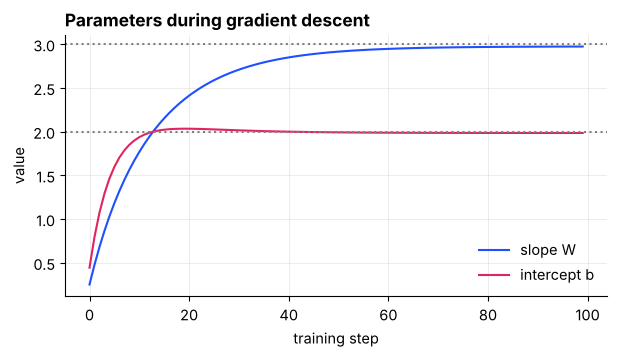

In [5]:
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)
X = rng.uniform(-1, 1, (200, 1)).astype("float32")
y = (3 * X[:, 0] + 2 + rng.normal(0, 0.2, 200)).astype("float32")

W = tf.Variable(tf.zeros((1,)))
b = tf.Variable(0.0)
opt = tf.keras.optimizers.SGD(learning_rate=0.1)
trace = []
for step in range(100):
    with tf.GradientTape() as tape:
        pred = X[:, 0] * W + b
        loss = tf.reduce_mean((pred - y) ** 2)
    grads = tape.gradient(loss, [W, b])
    opt.apply_gradients(zip(grads, [W, b]))
    trace.append((float(W[0]), float(b)))
print(f"learned slope={W.numpy()[0]:.3f}, intercept={b.numpy():.3f}, final loss={loss.numpy():.4f}")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot([t[0] for t in trace], label="slope W"); ax.plot([t[1] for t in trace], label="intercept b")
ax.axhline(3, ls=":", color="grey"); ax.axhline(2, ls=":", color="grey")
ax.set(xlabel="training step", ylabel="value", title="Parameters during gradient descent"); ax.legend()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import matplotlib.pyplot as plt</code></td><td>Import Matplotlib&#x27;s plotting interface under the short name <code>plt</code>.</td></tr>
<tr><td><code>rng = np.random.default_rng(0)</code></td><td>Seeded NumPy generator.</td></tr>
<tr><td><code>X = rng.uniform(-1, 1, (200, 1)).astype(&quot;float32&quot;)</code></td><td>200 inputs between -1 and 1, as float32.</td></tr>
<tr><td><code>y = (3 * X[:, 0] + 2 + rng.normal(0, 0.2, 200)).astype(&quot;float32&quot;)</code></td><td>True slope 3, intercept 2.</td></tr>
<tr><td><code>W = tf.Variable(tf.zeros((1,)))</code></td><td>Slope, initialised at 0.</td></tr>
<tr><td><code>b = tf.Variable(0.0)</code></td><td>Intercept.</td></tr>
<tr><td><code>opt = tf.keras.optimizers.SGD(learning_rate=0.1)</code></td><td>Plain stochastic gradient descent.</td></tr>
<tr><td><code>trace = []</code></td><td>Records the parameters after each step.</td></tr>
<tr><td><code>for step in range(100):</code></td><td>Loop over <code>range(100)</code>, naming each item <code>step</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;with tf.GradientTape() as tape:</code></td><td>Record the operations below.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;pred = X[:, 0] * W + b</code></td><td>Forward pass.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;loss = tf.reduce_mean((pred - y) ** 2)</code></td><td>MSE loss.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;grads = tape.gradient(loss, [W, b])</code></td><td>Backward pass: gradients for every variable.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;opt.apply_gradients(zip(grads, [W, b]))</code></td><td>Update: variable -= learning_rate * gradient.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;trace.append((float(W[0]), float(b)))</code></td><td>Store current slope and intercept.</td></tr>
<tr><td><code>print(f&quot;learned slope={W.numpy()[0]:.3f}, intercept={b.numpy():.3f}, final loss={loss.numpy():.4f}&quot;)</code></td><td>Close to 3 and 2.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(7, 3.4))</code></td><td>One panel.</td></tr>
<tr><td><code>ax.plot([t[0] for t in trace], label=&quot;slope W&quot;); ax.plot([t[1] for t in trace], label=&quot;intercept b&quot;)</code></td><td>Both parameters over time.</td></tr>
<tr><td><code>ax.axhline(3, ls=&quot;:&quot;, color=&quot;grey&quot;); ax.axhline(2, ls=&quot;:&quot;, color=&quot;grey&quot;)</code></td><td>Dotted lines at the true values.</td></tr>
<tr><td><code>ax.set(xlabel=&quot;training step&quot;, ylabel=&quot;value&quot;, title=&quot;Parameters during gradient descent&quot;); ax.legend()</code></td><td>Labels and legend.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

## 26.4 Speed: tf.function · *Advanced*

Decorating a Python function with `@tf.function` compiles it into a TensorFlow graph, which usually runs faster and can be exported. Keras does this for you inside `fit()`.

**Graph compilation**

In [6]:
@tf.function
def train_step(X, y):
    with tf.GradientTape() as tape:
        loss = tf.reduce_mean((X[:, 0] * W + b - y) ** 2)
    grads = tape.gradient(loss, [W, b])
    opt.apply_gradients(zip(grads, [W, b]))
    return loss

print(float(train_step(X, y)))

0.0416865348815918


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>@tf.function</code></td><td>Traced once per input signature, then runs as an optimised graph.</td></tr>
<tr><td><code>def train_step(X, y):</code></td><td>Define a function <code>train_step</code> that takes <code>X</code> and <code>y</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;with tf.GradientTape() as tape:</code></td><td>Record the operations below.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;loss = tf.reduce_mean((X[:, 0] * W + b - y) ** 2)</code></td><td>MSE loss.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;grads = tape.gradient(loss, [W, b])</code></td><td>Gradients for W and b.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;opt.apply_gradients(zip(grads, [W, b]))</code></td><td>Update the variables.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return loss</code></td><td>Send <code>loss</code> back to the caller.</td></tr>
<tr><td><code>print(float(train_step(X, y)))</code></td><td>Run one compiled step and show the loss.</td></tr>
</table>
</details>

> **🐞 Bug hunt** · **Python side-effects inside `tf.function`**
>
> `print()` inside a `tf.function` runs only while the function is being traced (usually once), not on every call; use `tf.print()` instead. Avoid changing Python lists or global variables inside it. While debugging, run eagerly with `tf.config.run_functions_eagerly(True)`.

## 26.5 Input pipelines with tf.data · *Intermediate*

> **📖 Definitions**
>
> **Mini-batch**: a small subset of the training data (such as 32 samples) used for one gradient update.


`tf.data.Dataset` streams data in shuffled mini-batches, applies transformations in parallel, and prefetches the next batch while the model trains. It scales from NumPy arrays to datasets far larger than memory.

**Building a dataset pipeline**

In [7]:
Xd = rng.normal(size=(1000, 4)).astype("float32")
yd = (Xd.sum(axis=1) > 0).astype("int32")
ds = tf.data.Dataset.from_tensor_slices((Xd, yd))
ds = (ds.shuffle(buffer_size=1000, seed=0)
        .map(lambda x, t: (x * 2.0, t), num_parallel_calls=tf.data.AUTOTUNE)
        .batch(32)
        .prefetch(tf.data.AUTOTUNE))
for xb, tb in ds.take(1):
    print(xb.shape, tb.shape, tb[:8].numpy())
print("batches per epoch:", len(list(ds)))

(32, 4) (32,) [0 1 0 1 0 0 0 1]
batches per epoch: 32


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>Xd = rng.normal(size=(1000, 4)).astype(&quot;float32&quot;)</code></td><td>1000 samples, 4 features.</td></tr>
<tr><td><code>yd = (Xd.sum(axis=1) &gt; 0).astype(&quot;int32&quot;)</code></td><td>Label 1 if the features sum to more than 0.</td></tr>
<tr><td><code>ds = tf.data.Dataset.from_tensor_slices((Xd, yd))</code></td><td>One element per row: (features, label).</td></tr>
<tr><td><code>ds = (ds.shuffle(buffer_size=1000, seed=0)</code></td><td>Shuffle within a buffer (use the dataset size if it fits in memory).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;.map(lambda x, t: (x * 2.0, t), num_parallel_calls=tf.data.AUTOTUNE)</code></td><td>Apply a transformation to each element, in parallel.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;.batch(32)</code></td><td>Group into mini-batches of 32.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;.prefetch(tf.data.AUTOTUNE))</code></td><td>Prepare the next batch while the current one trains.</td></tr>
<tr><td><code>for xb, tb in ds.take(1):</code></td><td>Peek at one batch.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(xb.shape, tb.shape, tb[:8].numpy())</code></td><td>(32, 4) features, (32,) labels, and the first 8 labels.</td></tr>
<tr><td><code>print(&quot;batches per epoch:&quot;, len(list(ds)))</code></td><td>ceil(1000 / 32) = 32.</td></tr>
</table>
</details>

> **💡 Tip** · **When to use tf.data**
>
> For small in-memory tables, passing NumPy arrays straight to `model.fit(X, y, batch_size=32)` is simplest. Reach for `tf.data` for large datasets, images on disk (`tf.keras.utils.image_dataset_from_directory`), text, or heavy on-the-fly augmentation.

## 26.6 Reproducibility · *Beginner*

**One call seeds Python, NumPy and TensorFlow**

In [8]:
tf.keras.utils.set_random_seed(42)
print(tf.random.uniform((3,)).numpy().round(4))
tf.keras.utils.set_random_seed(42)
print(tf.random.uniform((3,)).numpy().round(4))

[0.6646 0.441  0.3529]
[0.6646 0.441  0.3529]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>tf.keras.utils.set_random_seed(42)</code></td><td>Sets the Python <code>random</code>, NumPy and TensorFlow seeds together.</td></tr>
<tr><td><code>print(tf.random.uniform((3,)).numpy().round(4))</code></td><td>Three random numbers.</td></tr>
<tr><td><code>tf.keras.utils.set_random_seed(42)</code></td><td>Reset all seeds to the same value.</td></tr>
<tr><td><code>print(tf.random.uniform((3,)).numpy().round(4))</code></td><td>Identical.</td></tr>
</table>
</details>

> **🔬 Research practice** · **Determinism on GPUs**
>
> Some GPU operations are non-deterministic even with seeds. For bit-exact reruns call `tf.config.experimental.enable_op_determinism()` (slower). In practice, report the mean and standard deviation over several seeds: deep-learning results vary run to run.

> **✍️ Try it yourself**
>
> 1. Use `GradientTape` to find the minimum of f(x) = (x − 4)² + 1 by gradient descent, starting from x = 0.
> 2. Extend the manual training loop to two input features.
> 3. Build a `tf.data` pipeline from the breast-cancer data (`load_breast_cancer`) with batches of 64.
>
> *Worked solutions:* [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 26*.

---

⬅️ [Chapter 25: Interpreting, explaining and saving models](../part-5-scikit-learn/25-sklearn-interpret.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 27: Neural networks with Keras](27-keras-mlp.ipynb) ➡️